    Point (p)      y(p)
0   (-2, 0.5)  0.056531
1   (-1.5, 1)  0.056531
2   (-1, 0.5)  0.056531
3   (-1.5, 0)  0.056531
4   (0.75, 1)  0.056555
5   (1, 0.75)  0.056534
6   (1, 1.25)  0.056532
7   (1.25, 1)  0.056531
8      (2, 2) -0.550000
9   (-1.3, 0)  0.009898
10     (0, 0) -0.543262
11  (-2, 1.5) -0.467915


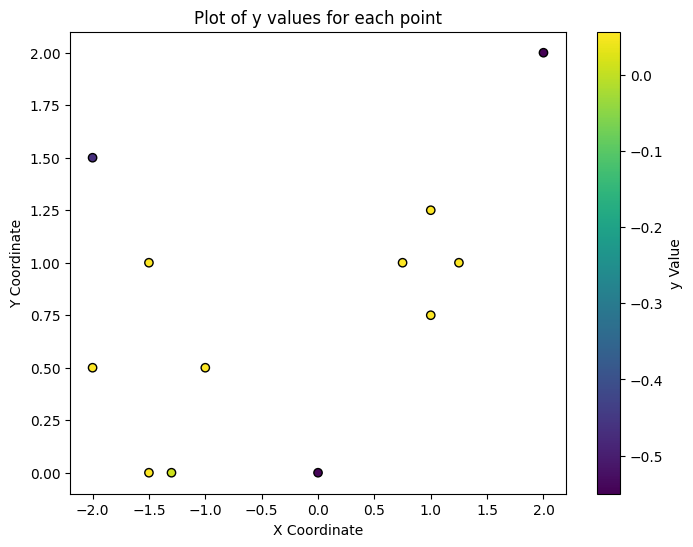

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define the function to compute y
def compute_y(p, w1, w2, W2, b2):
    p = np.array(p)
    w1 = np.array(w1)
    w2 = np.array(w2)
    
    # Radial Basis Layer
    term1 = np.exp(-np.linalg.norm(p - w1)**2 / (2 * 0.5**2))  # RBF 1
    term2 = np.exp(-np.linalg.norm(p - w2)**2 / (2 * 0.25**2))  # RBF 2
    a1 = np.array([term1, term2])  # RBF activations
    
    # Linear Layer
    a2 = np.dot(W2, a1) + b2  # Linear combination
    return a2


# Input points
points = [(-2, 0.5), (-1.5, 1), (-1, 0.5), (-1.5, 0), (0.75, 1), (1, 0.75), 
          (1, 1.25), (1.25, 1), (2, 2), (-1.3, 0), (0, 0), (-2, 1.5)]
w1 = (-1.5, 0.5)
w2 = (1,1)
W2 = np.array([1, 1])  # Weight vector for linear layer
B2 = -0.55  # Bias term

# Compute y for each point
results = [(p, compute_y(p, w1, w2, W2, B2)) for p in points]

# Extract the y values from the results
points, y_values = zip(*results)

# Convert results to a DataFrame for better display
df_results = pd.DataFrame(results, columns=["Point (p)", "y(p)"])
print(df_results)

# Plot y values
plt.figure(figsize=(8, 6))
plt.scatter([p[0] for p in points], [p[1] for p in points], c=y_values, cmap='viridis', edgecolors='k')
plt.colorbar(label='y Value')
plt.title('Plot of y values for each point')
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.show()


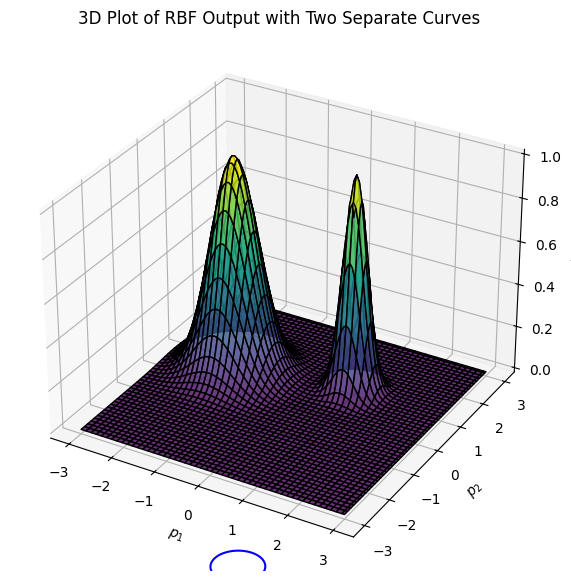

In [88]:
import numpy as np
import matplotlib.pyplot as plt

# Define the RBF function
def compute_y(p, w1, w2, W2, b2):
    p = np.array(p)
    w1 = np.array(w1)
    w2 = np.array(w2)
    
    # Radial Basis Layer
    term1 = np.exp(-np.linalg.norm(p - w1)**2 / (2 * 0.5**2))  # RBF 1
    term2 = np.exp(-np.linalg.norm(p - w2)**2 / (2 * 0.25**2))  # RBF 2
    a1 = np.array([term1, term2])  # RBF activations
    
    # Linear Layer
    a2 = np.dot(W2, a1) + b2  # Linear combination
    return a2

# Define parameters
w1 = (-1.5, 0.5)  # Center of the first RBF
w2 = (1, 1)       # Center of the second RBF
W2 = np.array([1, 1])  # Weights for linear layer
B2 = 0           # Bias

# Generate a grid of points
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)

# Compute RBF output for the grid
Z = np.array([compute_y((xi, yi), w1, w2, W2, B2) for xi, yi in zip(X.flatten(), Y.flatten())])
Z = Z.reshape(X.shape)

# Plot the 3D surface
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='k', alpha=0.8)

# Add contour lines
ax.contour(X, Y, Z, levels=0, zdir='z', offset=-1, colors='red')  # Zero plane
ax.contour(X, Y, Z, levels=[0.5], zdir='z', offset=-1, colors='blue')  # First curve
ax.contour(X, Y, Z, levels=[-0.5], zdir='z', offset=-1, colors='green')  # Second curve

# Labels and title
ax.set_title("3D Plot of RBF Output with Two Separate Curves")
ax.set_xlabel("$p_1$")
ax.set_ylabel("$p_2$")
ax.set_zlabel("$y$")
plt.show()
